In [ ]:
import pandas as pd
import numpy as np

from sklearn.metrics.pairwise import cosine_similarity

movies = pd.read_csv(
    "data/processed/content_candidates.csv"
)

print("=== Content-Based Candidates ===")
print(movies.shape)
print(movies.head())

=== Content-Based Candidates ===
(9708, 26)
   movieId                               title  \
0        1                    Toy Story (1995)   
1        2                      Jumanji (1995)   
2        3             Grumpier Old Men (1995)   
3        4            Waiting to Exhale (1995)   
4        5  Father of the Bride Part II (1995)   

                                        genres  rating_count  rating_mean  \
0  Adventure|Animation|Children|Comedy|Fantasy         215.0     3.920930   
1                   Adventure|Children|Fantasy         110.0     3.431818   
2                               Comedy|Romance          52.0     3.259615   
3                         Comedy|Drama|Romance           7.0     2.357143   
4                                       Comedy          49.0     3.071429   

   weighted_rating  rating_difference  normalized_rating  Action  Adventure  \
0         3.902291          -0.018639           0.767281       0          1   
1         3.437630           0.005

In [2]:
available_genres = [
    "Action", "Adventure", "Animation",
    "Children", "Comedy", "Crime",
    "Documentary", "Drama", "Fantasy",
    "Film-Noir", "Horror", "Musical",
    "Mystery", "Romance", "Sci-Fi",
    "Thriller", "War", "Western"
]

print("Number of genres:", len(available_genres))

Number of genres: 18


In [3]:
selected_genres = [
    "Action",
    "Sci-Fi",
    "Thriller"
]

user_vector = np.array([
    1 if genre in selected_genres else 0
    for genre in available_genres
])

print("=== User Genre Vector ===")
print(user_vector)
print("Vector shape:", user_vector.shape)

=== User Genre Vector ===
[1 0 0 0 0 0 0 0 0 0 0 0 0 0 1 1 0 0]
Vector shape: (18,)


In [4]:
movie_vectors = movies[available_genres].to_numpy()

print("=== Movie Genre Vectors ===")
print(movie_vectors[:5])

print("\nMatrix shape:", movie_vectors.shape)

=== Movie Genre Vectors ===
[[0 1 1 1 1 0 0 0 1 0 0 0 0 0 0 0 0 0]
 [0 1 0 1 0 0 0 0 1 0 0 0 0 0 0 0 0 0]
 [0 0 0 0 1 0 0 0 0 0 0 0 0 1 0 0 0 0]
 [0 0 0 0 1 0 0 1 0 0 0 0 0 1 0 0 0 0]
 [0 0 0 0 1 0 0 0 0 0 0 0 0 0 0 0 0 0]]

Matrix shape: (9708, 18)


In [5]:
user_vector_2d = user_vector.reshape(1, -1)

similarity_scores = cosine_similarity(
    user_vector_2d,
    movie_vectors
)

print("=== Cosine Similarity Scores ===")
print(similarity_scores)

print("\nShape:", similarity_scores.shape)

=== Cosine Similarity Scores ===
[[0.         0.         0.         ... 0.         0.40824829 0.        ]]

Shape: (1, 9708)


In [6]:
movies["genre_similarity"] = similarity_scores[0]

print("=== Movies with Genre Similarity ===")

print(
    movies[
        ["title", "genres", "genre_similarity"]
    ].head(10).to_string(index=False)
)

=== Movies with Genre Similarity ===
                             title                                      genres  genre_similarity
                  Toy Story (1995) Adventure|Animation|Children|Comedy|Fantasy          0.000000
                    Jumanji (1995)                  Adventure|Children|Fantasy          0.000000
           Grumpier Old Men (1995)                              Comedy|Romance          0.000000
          Waiting to Exhale (1995)                        Comedy|Drama|Romance          0.000000
Father of the Bride Part II (1995)                                      Comedy          0.000000
                       Heat (1995)                       Action|Crime|Thriller          0.666667
                    Sabrina (1995)                              Comedy|Romance          0.000000
               Tom and Huck (1995)                          Adventure|Children          0.000000
               Sudden Death (1995)                                      Action          0.

In [7]:
top_similar_movies = movies.sort_values(
    by="genre_similarity",
    ascending=False
)

print("=== Top 10 Genre Similar Movies ===")

print(
    top_similar_movies[
        [
            "title",
            "genres",
            "genre_similarity",
            "normalized_rating"
        ]
    ].head(10).to_string(index=False)
)

=== Top 10 Genre Similar Movies ===
                                    title                      genres  genre_similarity  normalized_rating
                             Gamer (2009)      Action|Sci-Fi|Thriller               1.0           0.566120
          X-Men Origins: Wolverine (2009)      Action|Sci-Fi|Thriller               1.0           0.365604
Lawnmower Man 2: Beyond Cyberspace (1996)      Action|Sci-Fi|Thriller               1.0           0.358616
                        Surrogates (2009)      Action|Sci-Fi|Thriller               1.0           0.453260
                          eXistenZ (1999)      Action|Sci-Fi|Thriller               1.0           0.696394
                  I Am Number Four (2011) Action|Sci-Fi|Thriller|IMAX               1.0           0.517649
                         Screamers (1995)      Action|Sci-Fi|Thriller               1.0           0.551699
                          Predator (1987)      Action|Sci-Fi|Thriller               1.0           0.612413
 

In [8]:
alpha = 0.7

movies["recommendation_score"] = (
    alpha * movies["genre_similarity"]
    + (1 - alpha) * movies["normalized_rating"]
)

print("=== Recommendation Scores ===")

print(
    movies[
        [
            "title",
            "genre_similarity",
            "normalized_rating",
            "recommendation_score"
        ]
    ].head(10).to_string(index=False)
)

=== Recommendation Scores ===
                             title  genre_similarity  normalized_rating  recommendation_score
                  Toy Story (1995)          0.000000           0.767281              0.230184
                    Jumanji (1995)          0.000000           0.550302              0.165091
           Grumpier Old Men (1995)          0.000000           0.485398              0.145619
          Waiting to Exhale (1995)          0.000000           0.360107              0.108032
Father of the Bride Part II (1995)          0.000000           0.413343              0.124003
                       Heat (1995)          0.666667           0.769195              0.697425
                    Sabrina (1995)          0.000000           0.455503              0.136651
               Tom and Huck (1995)          0.000000           0.450119              0.135036
               Sudden Death (1995)          0.577350           0.471945              0.545729
                  GoldenEye (1

In [9]:
top_recommendations = movies.sort_values(
    by="recommendation_score",
    ascending=False
).head(10)

print("=== Top 10 Recommended Movies ===")

print(
    top_recommendations[
        [
            "title",
            "genres",
            "genre_similarity",
            "normalized_rating",
            "recommendation_score"
        ]
    ].to_string(index=False)
)

=== Top 10 Recommended Movies ===
                            title                      genres  genre_similarity  normalized_rating  recommendation_score
               Matrix, The (1999)      Action|Sci-Fi|Thriller               1.0           0.891570              0.967471
              Blade Runner (1982)      Action|Sci-Fi|Thriller               1.0           0.839098              0.951729
           Terminator, The (1984)      Action|Sci-Fi|Thriller               1.0           0.751691              0.925507
            V for Vendetta (2006) Action|Sci-Fi|Thriller|IMAX               1.0           0.742929              0.922879
               Equilibrium (2002)      Action|Sci-Fi|Thriller               1.0           0.722244              0.916673
                  eXistenZ (1999)      Action|Sci-Fi|Thriller               1.0           0.696394              0.908918
                 Hangar 18 (1980)      Action|Sci-Fi|Thriller               1.0           0.657859              0.89735

In [10]:
matched_movies = movies[
    movies["genre_similarity"] > 0
].copy()

print("=== Movies Matching User Genres ===")
print("Number of matching movies:", len(matched_movies))

=== Movies Matching User Genres ===
Number of matching movies: 3456


In [11]:
final_recommendations = matched_movies.sort_values(
    by="recommendation_score",
    ascending=False
).head(10)

print("=== Final Top 10 Recommendations ===")

print(
    final_recommendations[
        [
            "title",
            "genres",
            "genre_similarity",
            "normalized_rating",
            "recommendation_score"
        ]
    ].to_string(index=False)
)

=== Final Top 10 Recommendations ===
                            title                      genres  genre_similarity  normalized_rating  recommendation_score
               Matrix, The (1999)      Action|Sci-Fi|Thriller               1.0           0.891570              0.967471
              Blade Runner (1982)      Action|Sci-Fi|Thriller               1.0           0.839098              0.951729
           Terminator, The (1984)      Action|Sci-Fi|Thriller               1.0           0.751691              0.925507
            V for Vendetta (2006) Action|Sci-Fi|Thriller|IMAX               1.0           0.742929              0.922879
               Equilibrium (2002)      Action|Sci-Fi|Thriller               1.0           0.722244              0.916673
                  eXistenZ (1999)      Action|Sci-Fi|Thriller               1.0           0.696394              0.908918
                 Hangar 18 (1980)      Action|Sci-Fi|Thriller               1.0           0.657859              0.89

In [12]:
print("=== Recommendation Validation ===")

print("Total candidate movies:", len(movies))

print(
    "Movies matching selected genres:",
    len(matched_movies)
)

print(
    "Minimum recommendation score:",
    movies["recommendation_score"].min()
)

print(
    "Maximum recommendation score:",
    movies["recommendation_score"].max()
)

print(
    "Missing recommendation scores:",
    movies["recommendation_score"].isnull().sum()
)

print(
    "Number of recommendations:",
    len(final_recommendations)
)

=== Recommendation Validation ===
Total candidate movies: 9708
Movies matching selected genres: 3456
Minimum recommendation score: 0.02334169262592393
Maximum recommendation score: 0.9674710881331363
Missing recommendation scores: 0
Number of recommendations: 10


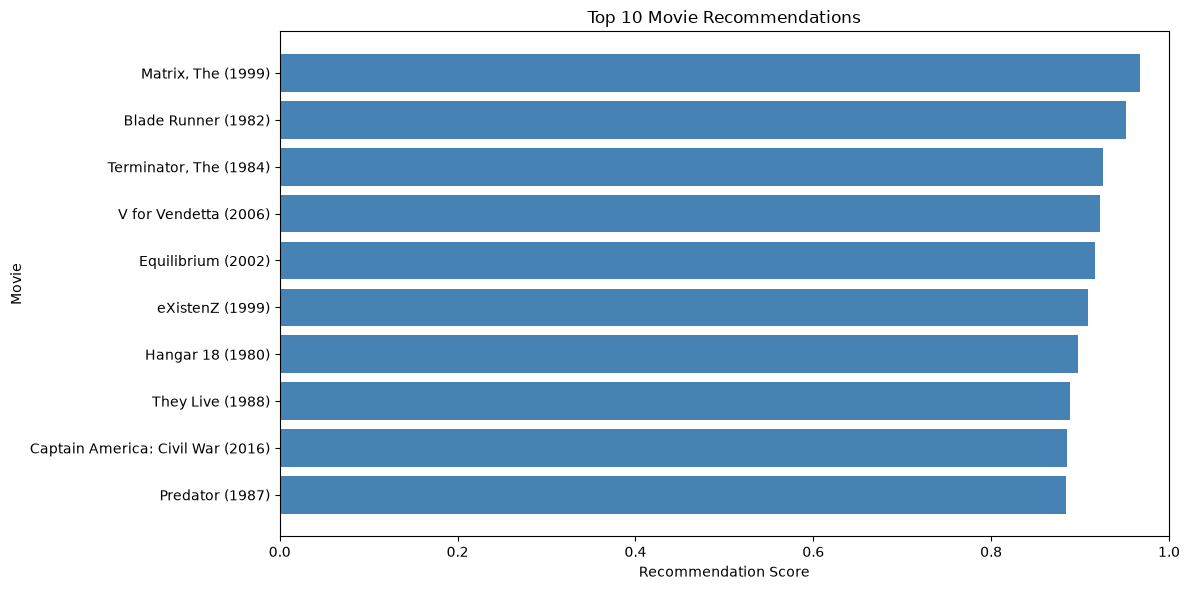

In [13]:
import matplotlib.pyplot as plt

plot_data = final_recommendations.sort_values(
    by="recommendation_score",
    ascending=True
)

plt.figure(figsize=(12, 6))

plt.barh(
    plot_data["title"],
    plot_data["recommendation_score"],
    color="steelblue"
)

plt.title("Top 10 Movie Recommendations")
plt.xlabel("Recommendation Score")
plt.ylabel("Movie")
plt.xlim(0, 1)

plt.tight_layout()
plt.show()